In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile

from IPython.display import display

np.random.seed(42)

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
os.makedirs("carebridge_dataset", exist_ok=True)
n_patients = 1500
patient_ids = np.arange(10001, 10001 + n_patients)
patients = pd.DataFrame({
    "Patient_ID": patient_ids,
    "Age_Group": np.random.choice(
        ["0-17", "18-35", "36-50", "51-65", "66+"],
        n_patients,
        p=[0.12, 0.28, 0.25, 0.20, 0.15]
    ),
    "Locality": np.random.choice(
        ["Urban", "Suburban", "Rural"],
        n_patients,
        p=[0.50, 0.30, 0.20]
    ),
    "Previous_Visits": np.random.poisson(3, n_patients),
    "Previous_No_Shows": np.zeros(n_patients, dtype=int)
})
departments = [
    "Cardiology", "Orthopedics", "Dermatology",
    "Neurology", "Pediatrics", "General Medicine"
]

doctors = pd.DataFrame({
    "Doctor_ID": np.arange(201, 231),
    "Doctor_Name": [
        f"Doctor_{i}" for i in range(1, 31)
    ],
    "Specialty": np.random.choice(departments, 30),
    "Clinic_Day": np.random.choice(
        ["Monday", "Tuesday", "Wednesday",
         "Thursday", "Friday", "Saturday"], 30
    ),
    "Available_Slots": np.random.randint(20, 41, 30)
})
calendar_dates = pd.date_range(
    start="2025-01-01",
    end="2026-12-31",
    freq="D"
)

calendar = pd.DataFrame({"Appointment_Date": calendar_dates})
calendar["Weekday"] = calendar["Appointment_Date"].dt.day_name()
calendar["Is_Weekend"] = (
    calendar["Weekday"].isin(["Saturday", "Sunday"])
).astype(int)
calendar["Is_Holiday"] = (
    (calendar["Appointment_Date"].dt.month == 1) &
    (calendar["Appointment_Date"].dt.day == 1)
).astype(int)

calendar["Season"] = calendar["Appointment_Date"].dt.month.map(
    lambda m: (
        "Winter" if m in [12, 1, 2]
        else "Summer" if m in [3, 4, 5]
        else "Monsoon" if m in [6, 7, 8, 9]
        else "Autumn"
    )
)
n_appointments = 5000

appointment_dates = pd.to_datetime(
    np.random.choice(
        pd.date_range("2025-01-01", "2026-12-30", freq="D"),
        n_appointments
    )
)
lead_days = np.random.choice(
    [0, 1, 2, 3, 5, 7, 10, 14, 21, 30],
    n_appointments,
    p=[0.12, 0.12, 0.12, 0.10, 0.13,
       0.12, 0.09, 0.08, 0.07, 0.05]
)

booking_dates = (
    appointment_dates -
    pd.to_timedelta(lead_days, unit="D")
)

appointment_patient_ids = np.random.choice(
    patient_ids, n_appointments
)

appointment_doctor_ids = np.random.choice(
    doctors["Doctor_ID"], n_appointments
)

appointment_departments = np.random.choice(
    departments, n_appointments
)
no_show_probability = (
    0.12
    + 0.008 * lead_days
    + np.where(appointment_dates.dayofweek == 0, 0.04, 0)
    + np.where(appointment_dates.dayofweek == 5, 0.03, 0)
)

no_show_probability = np.clip(
    no_show_probability, 0.05, 0.65
)

is_no_show = (
    np.random.random(n_appointments) < no_show_probability
)

appointments = pd.DataFrame({
    "Appointment_ID": np.arange(50001, 50001 + n_appointments),
    "Patient_ID": appointment_patient_ids,
    "Doctor_ID": appointment_doctor_ids,
    "Appointment_Date": appointment_dates,
    "Booking_Date": booking_dates,
    "Department": appointment_departments,
    "Status": np.where(is_no_show, "No-show", "Show"),
    "Waiting_Days": lead_days
})
missing_status_idx = np.random.choice(
    appointments.index, 75, replace=False
)
appointments.loc[missing_status_idx, "Status"] = np.nan

department_variants = {
    "Cardiology": "cardiology",
    "Orthopedics": "Orthopaedics",
    "Dermatology": "dermatology ",
    "Neurology": "NEUROLOGY",
    "Pediatrics": "Paediatrics",
    "General Medicine": "General medicine"
}

variant_idx = np.random.choice(
    appointments.index, 120, replace=False
)

for idx in variant_idx:
    dept = appointments.loc[idx, "Department"]
    appointments.loc[idx, "Department"] = department_variants.get(
        dept, dept
    )

# 3. Invalid waiting days and bookings after appointment
invalid_idx = np.random.choice(
    appointments.index, 40, replace=False
)

appointments.loc[invalid_idx, "Waiting_Days"] = np.random.choice(
    [-10, -3, 1000], len(invalid_idx)
)

appointments.loc[invalid_idx[:20], "Booking_Date"] = (
    appointments.loc[invalid_idx[:20], "Appointment_Date"]
    + pd.to_timedelta(5, unit="D")
)

# 4. Duplicate bookings
duplicate_rows = appointments.sample(
    50, random_state=42
)

appointments = pd.concat(
    [appointments, duplicate_rows],
    ignore_index=True
)

# -------------------------------
# 5. REMINDERS DATASET
# -------------------------------
# Some appointments have no reminder record.
reminder_appointment_ids = np.random.choice(
    appointments["Appointment_ID"].drop_duplicates(),
    size=3800,
    replace=False
)

reminders = pd.DataFrame({
    "Reminder_ID": np.arange(90001, 90001 + len(reminder_appointment_ids)),
    "Appointment_ID": reminder_appointment_ids,
    "Reminder_Type": np.random.choice(
        ["SMS", "Phone Call", "Email"],
        len(reminder_appointment_ids),
        p=[0.65, 0.20, 0.15]
    ),
    "Sent_Status": np.random.choice(
        ["Sent", "Failed"],
        len(reminder_appointment_ids),
        p=[0.93, 0.07]
    ),
    "Patient_Response": np.random.choice(
        ["Confirmed", "Declined", "No Response"],
        len(reminder_appointment_ids),
        p=[0.45, 0.10, 0.45]
    )
})

# Incomplete reminder records
reminder_missing_idx = np.random.choice(
    reminders.index, 100, replace=False
)
reminders.loc[reminder_missing_idx, "Sent_Status"] = np.nan

# -------------------------------
# UPDATE PATIENT HISTORY
# -------------------------------
# Generate prior history for this synthetic scenario.
history = appointments.dropna(subset=["Status"]).copy()
history["No_Show_Flag"] = (
    history["Status"].str.lower() == "no-show"
).astype(int)

patient_history = history.groupby("Patient_ID").agg(
    Previous_Visits=("Appointment_ID", "nunique"),
    Previous_No_Shows=("No_Show_Flag", "sum")
).reset_index()

patients = patients.drop(
    columns=["Previous_Visits", "Previous_No_Shows"]
).merge(patient_history, on="Patient_ID", how="left")

patients[["Previous_Visits", "Previous_No_Shows"]] = (
    patients[["Previous_Visits", "Previous_No_Shows"]]
    .fillna(0).astype(int)
)

# -------------------------------
# SAVE ALL FILES
# -------------------------------
datasets = {
    "appointments.csv": appointments,
    "patients.csv": patients,
    "doctors.csv": doctors,
    "reminders.csv": reminders,
    "calendar.csv": calendar
}

for filename, df in datasets.items():
    df.to_csv(
        f"carebridge_dataset/{filename}",
        index=False
    )

# Zip the five files for Excel and later use
with zipfile.ZipFile(
    "CareBridge_Synthetic_Dataset.zip", "w"
) as zip_file:
    for filename in datasets:
        zip_file.write(
            f"carebridge_dataset/{filename}",
            arcname=filename
        )

print("All five datasets generated successfully!")
for filename, df in datasets.items():
    print(f"{filename}: {df.shape[0]} rows, {df.shape[1]} columns")


All five datasets generated successfully!
appointments.csv: 5050 rows, 8 columns
patients.csv: 1500 rows, 5 columns
doctors.csv: 30 rows, 5 columns
reminders.csv: 3800 rows, 5 columns
calendar.csv: 730 rows, 5 columns


In [4]:

print("APPOINTMENTS")
display(appointments.head())

print("PATIENTS")
display(patients.head())

print("DOCTORS")
display(doctors.head())

print("REMINDERS")
display(reminders.head())

print("CALENDAR")
display(calendar.head())

print("\nDataset shapes:")
for filename, df in datasets.items():
    print(filename, df.shape)


APPOINTMENTS


,Appointment_ID,Patient_ID,Doctor_ID,Appointment_Date,Booking_Date,Department,Status,Waiting_Days
0,50001,11017,223,2026-08-14,2026-08-12,Dermatology,Show,2
1,50002,10739,207,2025-08-23,2025-07-24,Orthopedics,Show,30
2,50003,10151,224,2025-12-31,2025-12-24,General Medicine,No-show,7
3,50004,11319,203,2026-06-16,2026-06-02,Orthopedics,Show,14
4,50005,10087,217,2026-08-08,2026-08-01,Cardiology,Show,7


PATIENTS


,Patient_ID,Age_Group,Locality,Previous_Visits,Previous_No_Shows
0,10001,36-50,Suburban,5,0
1,10002,51-65,Urban,3,0
2,10003,51-65,Suburban,2,1
3,10004,36-50,Urban,5,0
4,10005,0-17,Suburban,7,2


DOCTORS


...

REMINDERS


,Reminder_ID,Appointment_ID,Reminder_Type,Sent_Status,Patient_Response
0,90001,51328,Phone Call,Sent,No Response
1,90002,50276,SMS,Sent,Confirmed
2,90003,50935,Email,Sent,No Response
3,90004,53793,SMS,Sent,No Response
4,90005,50557,SMS,Sent,Confirmed


CALENDAR


,Appointment_Date,Weekday,Is_Weekend,Is_Holiday,Season
0,2025-01-01,Wednesday,0,1,Winter
1,2025-01-02,Thursday,0,0,Winter
2,2025-01-03,Friday,0,0,Winter
3,2025-01-04,Saturday,1,0,Winter
4,2025-01-05,Sunday,1,0,Winter



Dataset shapes:
appointments.csv (5050, 8)
patients.csv (1500, 5)
doctors.csv (30, 5)
reminders.csv (3800, 5)
calendar.csv (730, 5)


In [5]:

# Missing values
print("MISSING VALUES")
display(
    appointments.isnull().sum().to_frame("Missing_Count")
)

# Duplicate records
print("EXACT DUPLICATE ROWS:")
print(appointments.duplicated().sum())

print("\nDUPLICATE APPOINTMENT IDS:")
print(appointments["Appointment_ID"].duplicated().sum())

# Department inconsistencies
print("\nDEPARTMENT VALUES:")
print(sorted(appointments["Department"].dropna().unique()))

# Invalid waiting days
print("\nINVALID WAITING DAYS:")
print(
    appointments[
        (appointments["Waiting_Days"] < 0) |
        (appointments["Waiting_Days"] > 365)
    ][["Appointment_ID", "Waiting_Days"]].head(10)
)

# Booking dates after appointment dates
print("\nBOOKING DATE AFTER APPOINTMENT:")
print(
    (
        appointments["Booking_Date"] >
        appointments["Appointment_Date"]
    ).sum()
)

# Missing reminder fields
print("\nREMINDER MISSING VALUES:")
display(reminders.isnull().sum().to_frame("Missing_Count"))


MISSING VALUES


,Missing_Count
Appointment_ID,0
Patient_ID,0
Doctor_ID,0
Appointment_Date,0
Booking_Date,0
Department,0
Status,75
Waiting_Days,0


EXACT DUPLICATE ROWS:
50

DUPLICATE APPOINTMENT IDS:
50

DEPARTMENT VALUES:
['Cardiology', 'Dermatology', 'General Medicine', 'General medicine', 'NEUROLOGY', 'Neurology', 'Orthopaedics', 'Orthopedics', 'Paediatrics', 'Pediatrics', 'cardiology', 'dermatology ']

INVALID WAITING DAYS:
      Appointment_ID  Waiting_Days
47             50048          1000
253            50254            -3
271            50272           -10
343            50344          1000
372            50373            -3
481            50482            -3
529            50530            -3
690            50691            -3
754            50755            -3
1108           51109           -10

BOOKING DATE AFTER APPOINTMENT:
21

REMINDER MISSING VALUES:


,Missing_Count
Reminder_ID,0
Appointment_ID,0
Reminder_Type,0
Sent_Status,100
Patient_Response,0


In [6]:

import pandas as pd
import numpy as np
import os

DATA_DIR = "carebridge_dataset"

appointments = pd.read_csv(
    f"{DATA_DIR}/appointments.csv",
    parse_dates=["Appointment_Date", "Booking_Date"]
)

patients = pd.read_csv(f"{DATA_DIR}/patients.csv")
doctors = pd.read_csv(f"{DATA_DIR}/doctors.csv")
reminders = pd.read_csv(f"{DATA_DIR}/reminders.csv")
calendar = pd.read_csv(
    f"{DATA_DIR}/calendar.csv",
    parse_dates=["Appointment_Date"]
)

print("All datasets loaded successfully!")
print("Appointments:", appointments.shape)
print("Patients:", patients.shape)
print("Doctors:", doctors.shape)
print("Reminders:", reminders.shape)
print("Calendar:", calendar.shape)


All datasets loaded successfully!
Appointments: (5050, 8)
Patients: (1500, 5)
Doctors: (30, 5)
Reminders: (3800, 5)
Calendar: (730, 5)


In [7]:

print("Exact duplicate rows:", appointments.duplicated().sum())

# Remove exact duplicate rows
appointments = appointments.drop_duplicates().copy()

# Identify appointment IDs with multiple records
duplicate_ids = appointments[
    appointments.duplicated("Appointment_ID", keep=False)
].sort_values("Appointment_ID")

print("Appointment IDs with multiple records:",
      duplicate_ids["Appointment_ID"].nunique())

# Keep the first row per ID for this synthetic exercise.
# In real hospital data, conflicting records should be reviewed.
appointments = appointments.drop_duplicates(
    subset="Appointment_ID",
    keep="first"
).copy()

print("Shape after duplicate removal:", appointments.shape)
print("Remaining duplicate IDs:",
      appointments["Appointment_ID"].duplicated().sum())


Exact duplicate rows: 50
Appointment IDs with multiple records: 0
Shape after duplicate removal: (5000, 8)
Remaining duplicate IDs: 0


In [8]:

appointments["Department"] = (
    appointments["Department"]
    .astype("string")
    .str.strip()
    .str.lower()
)

department_mapping = {
    "cardiology": "Cardiology",
    "orthopedics": "Orthopedics",
    "orthopaedics": "Orthopedics",
    "dermatology": "Dermatology",
    "neurology": "Neurology",
    "pediatrics": "Pediatrics",
    "paediatrics": "Pediatrics",
    "general medicine": "General Medicine"
}

appointments["Department"] = (
    appointments["Department"].map(department_mapping)
)

print("Standardized department values:")
print(sorted(appointments["Department"].dropna().unique()))


Standardized department values:
['Cardiology', 'Dermatology', 'General Medicine', 'Neurology', 'Orthopedics', 'Pediatrics']


In [9]:

appointments["Status"] = (
    appointments["Status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

status_mapping = {
    "show": "Show",
    "no-show": "No-show",
    "noshow": "No-show"
}

appointments["Status"] = appointments["Status"].map(status_mapping)

print("Status counts, including missing:")
display(appointments["Status"].value_counts(dropna=False))

appointments["Attendance_Known"] = (
    appointments["Status"].notna()
).astype(int)

print("Records with known status:",
      appointments["Attendance_Known"].sum())

print("Records with unknown status:",
      appointments["Status"].isna().sum())


Status counts, including missing:


,count
Status,
Show,3965
No-show,960
NaN,75


Records with known status: 4925
Records with unknown status: 75


In [10]:

# Calculate the actual booking lead time
appointments["Lead_Days"] = (
    appointments["Appointment_Date"].dt.normalize()
    - appointments["Booking_Date"].dt.normalize()
).dt.days

# Identify invalid dates
invalid_booking_dates = appointments[
    appointments["Lead_Days"] < 0
]

print("Appointments booked after appointment date:",
      len(invalid_booking_dates))

# Identify extreme lead times
extreme_lead_days = appointments[
    appointments["Lead_Days"] > 365
]

print("Appointments with lead time over 365 days:",
      len(extreme_lead_days))

# Mark invalid lead times rather than inventing replacement values
appointments["Lead_Days_Valid"] = (
    appointments["Lead_Days"].between(0, 365)
)

appointments.loc[
    ~appointments["Lead_Days_Valid"], "Lead_Days"
] = np.nan

# Preserve the original field for audit purposes
appointments = appointments.rename(
    columns={"Waiting_Days": "Waiting_Days_Original"}
)

print("Lead-time validation completed.")
display(
    appointments[
        ["Appointment_ID", "Booking_Date",
         "Appointment_Date", "Waiting_Days_Original",
         "Lead_Days", "Lead_Days_Valid"]
    ].head(10)
)


Appointments booked after appointment date: 20
Appointments with lead time over 365 days: 0
Lead-time validation completed.


,Appointment_ID,Booking_Date,Appointment_Date,Waiting_Days_Original,Lead_Days,Lead_Days_Valid
0,50001,2026-08-12,2026-08-14,2,2.0,True
1,50002,2025-07-24,2025-08-23,30,30.0,True
2,50003,2025-12-24,2025-12-31,7,7.0,True
3,50004,2026-06-02,2026-06-16,14,14.0,True
4,50005,2026-08-01,2026-08-08,7,7.0,True
5,50006,2026-02-24,2026-03-01,5,5.0,True
6,50007,2026-05-15,2026-05-18,3,3.0,True
7,50008,2025-12-20,2025-12-20,0,0.0,True
8,50009,2025-06-02,2025-06-12,10,10.0,True
9,50010,2025-07-02,2025-07-04,2,2.0,True


In [11]:

# Remove exact duplicate reminder rows
reminders = reminders.drop_duplicates().copy()

# Standardize text fields
for col in ["Reminder_Type", "Sent_Status", "Patient_Response"]:
    reminders[col] = (
        reminders[col]
        .astype("string")
        .str.strip()
    )

# Standardize sent status
reminders["Sent_Status"] = (
    reminders["Sent_Status"]
    .str.lower()
    .map({"sent": "Sent", "failed": "Failed"})
)

# Standardize reminder type and response labels
reminders["Reminder_Type"] = (
    reminders["Reminder_Type"].str.lower().map({
        "sms": "SMS",
        "phone call": "Phone Call",
        "email": "Email"
    })
)

reminders["Patient_Response"] = (
    reminders["Patient_Response"].str.lower().map({
        "confirmed": "Confirmed",
        "declined": "Declined",
        "no response": "No Response"
    })
)

# One appointment may have multiple reminders.
# Aggregate them before merging to prevent duplicate appointment rows.
reminder_summary = (
    reminders.groupby("Appointment_ID", as_index=False)
    .agg(
        Reminder_Count=("Reminder_ID", "nunique"),
        Reminder_Type=(
            "Reminder_Type",
            lambda x: ", ".join(sorted(x.dropna().unique()))
        ),
        Reminder_Sent_Status=(
            "Sent_Status",
            lambda x: ", ".join(sorted(x.dropna().unique()))
        ),
        Patient_Response=(
            "Patient_Response",
            lambda x: ", ".join(sorted(x.dropna().unique()))
        )
    )
)

print("Reminder records:", len(reminders))
print("Appointments with reminder records:",
      reminder_summary["Appointment_ID"].nunique())

display(reminder_summary.head())


Reminder records: 3800
Appointments with reminder records: 3800


,Appointment_ID,Reminder_Count,Reminder_Type,Reminder_Sent_Status,Patient_Response
0,50001,1,Phone Call,Sent,Confirmed
1,50002,1,Email,Sent,Declined
2,50005,1,SMS,Sent,Confirmed
3,50006,1,Phone Call,Sent,No Response
4,50007,1,SMS,Sent,Confirmed


In [12]:

# Rename calendar date to avoid ambiguity
calendar_for_merge = calendar.rename(
    columns={"Appointment_Date": "Calendar_Date"}
)

# Merge patient details
master = appointments.merge(
    patients,
    on="Patient_ID",
    how="left",
    validate="many_to_one"
)

# Merge doctor details
master = master.merge(
    doctors,
    on="Doctor_ID",
    how="left",
    validate="many_to_one"
)

# Merge calendar information
master = master.merge(
    calendar_for_merge,
    left_on=master["Appointment_Date"].dt.normalize(),
    right_on=calendar_for_merge["Calendar_Date"],
    how="left",
    validate="many_to_one"
)

# Drop the extra merge key if pandas created one
if "key_0" in master.columns:
    master = master.drop(columns=["key_0"])

# Merge summarized reminder information
master = master.merge(
    reminder_summary,
    on="Appointment_ID",
    how="left",
    validate="one_to_one"
)

# No reminder record is different from a failed reminder
master["Reminder_Record_Available"] = (
    master["Reminder_Count"].notna()
).astype(int)

master["Reminder_Count"] = (
    master["Reminder_Count"].fillna(0).astype(int)
)

print("Master dataset created:", master.shape)
print("Unique appointment IDs:",
      master["Appointment_ID"].nunique())
print("Duplicate appointment IDs:",
      master["Appointment_ID"].duplicated().sum())

display(master.head())


Master dataset created: (5000, 29)
Unique appointment IDs: 5000
Duplicate appointment IDs: 0


,Appointment_ID,Patient_ID,Doctor_ID,Appointment_Date,Booking_Date,Department,Status,Waiting_Days_Original,Attendance_Known,Lead_Days,...,Calendar_Date,Weekday,Is_Weekend,Is_Holiday,Season,Reminder_Count,Reminder_Type,Reminder_Sent_Status,Patient_Response,Reminder_Record_Available
0,50001,11017,223,2026-08-14,2026-08-12,Dermatology,Show,2,1,2.0,...,2026-08-14,Friday,0,0,Monsoon,1,Phone Call,Sent,Confirmed,1
1,50002,10739,207,2025-08-23,2025-07-24,Orthopedics,Show,30,1,30.0,...,2025-08-23,Saturday,1,0,Monsoon,1,Email,Sent,Declined,1
2,50003,10151,224,2025-12-31,2025-12-24,General Medicine,No-show,7,1,7.0,...,2025-12-31,Wednesday,0,0,Winter,0,NaN,NaN,NaN,0
3,50004,11319,203,2026-06-16,2026-06-02,Orthopedics,Show,14,1,14.0,...,2026-06-16,Tuesday,0,0,Monsoon,0,NaN,NaN,NaN,0
4,50005,10087,217,2026-08-08,2026-08-01,Cardiology,Show,7,1,7.0,...,2026-08-08,Saturday,1,0,Monsoon,1,SMS,Sent,Confirmed,1


In [13]:

print("FINAL DATA QUALITY REPORT")
print("-" * 40)

print("Rows:", len(master))
print("Columns:", len(master.columns))
print("Duplicate appointment IDs:",
      master["Appointment_ID"].duplicated().sum())

print("\nMissing values:")
display(
    master.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing_Count")
    .query("Missing_Count > 0")
)

print("\nAttendance status:")
display(master["Status"].value_counts(dropna=False))

print("\nDepartment distribution:")
display(master["Department"].value_counts(dropna=False))

# Save cleaned appointment-level master data
master.to_csv(
    "CareBridge_Cleaned_Master.csv",
    index=False
)

print("\nCleaned master dataset saved successfully!")


FINAL DATA QUALITY REPORT
----------------------------------------
Rows: 5000
Columns: 29
Duplicate appointment IDs: 0

Missing values:


,Missing_Count
Patient_Response,1200
Reminder_Type,1200
Reminder_Sent_Status,1200
Status,75
Lead_Days,20



Attendance status:


,count
Status,
Show,3965
No-show,960
NaN,75



Department distribution:


,count
Department,
Neurology,877
Dermatology,858
Pediatrics,842
Orthopedics,814
Cardiology,805
General Medicine,804



Cleaned master dataset saved successfully!


In [14]:

# Create useful features for analysis

master["Appointment_Date"] = pd.to_datetime(
    master["Appointment_Date"], errors="coerce"
)
master["Booking_Date"] = pd.to_datetime(
    master["Booking_Date"], errors="coerce"
)

master["Appointment_Weekday"] = (
    master["Appointment_Date"].dt.day_name()
)
master["Appointment_Month"] = (
    master["Appointment_Date"].dt.month_name()
)

master["Is_Weekend"] = (
    master["Appointment_Weekday"]
    .isin(["Saturday", "Sunday"])
    .astype(int)
)

# Target: 1 = No-show, 0 = Show, missing = Unknown
master["No_Show_Flag"] = (
    master["Status"].map({"Show": 0, "No-show": 1})
)

# Booking lead-time categories
master["Lead_Time_Group"] = pd.cut(
    master["Lead_Days"],
    bins=[-0.001, 0, 3, 7, 14, 30, 365],
    labels=[
        "Same day", "1–3 days", "4–7 days",
        "8–14 days", "15–30 days", "31+ days"
    ],
    include_lowest=True
)

# Reminder indicators
master["Reminder_Received"] = (
    master["Reminder_Record_Available"]
    .fillna(0).astype(int)
)

master["Reminder_Sent_Successfully"] = (
    master["Reminder_Sent_Status"]
    .fillna("")
    .str.contains(r"\bSent\b", case=False, regex=True)
    .astype(int)
)

print("Feature engineering completed.")
display(master.head())


Feature engineering completed.


,Appointment_ID,Patient_ID,Doctor_ID,Appointment_Date,Booking_Date,Department,Status,Waiting_Days_Original,Attendance_Known,Lead_Days,...,Reminder_Type,Reminder_Sent_Status,Patient_Response,Reminder_Record_Available,Appointment_Weekday,Appointment_Month,No_Show_Flag,Lead_Time_Group,Reminder_Received,Reminder_Sent_Successfully
0,50001,11017,223,2026-08-14,2026-08-12,Dermatology,Show,2,1,2.0,...,Phone Call,Sent,Confirmed,1,Friday,August,0.0,1–3 days,1,1
1,50002,10739,207,2025-08-23,2025-07-24,Orthopedics,Show,30,1,30.0,...,Email,Sent,Declined,1,Saturday,August,0.0,15–30 days,1,1
2,50003,10151,224,2025-12-31,2025-12-24,General Medicine,No-show,7,1,7.0,...,NaN,NaN,NaN,0,Wednesday,December,1.0,4–7 days,0,0
3,50004,11319,203,2026-06-16,2026-06-02,Orthopedics,Show,14,1,14.0,...,NaN,NaN,NaN,0,Tuesday,June,0.0,8–14 days,0,0
4,50005,10087,217,2026-08-08,2026-08-01,Cardiology,Show,7,1,7.0,...,SMS,Sent,Confirmed,1,Saturday,August,0.0,4–7 days,1,1


In [15]:

known = master[master["No_Show_Flag"].notna()].copy()

total_appointments = len(master)
known_appointments = len(known)
unknown_appointments = total_appointments - known_appointments

show_count = (known["No_Show_Flag"] == 0).sum()
no_show_count = (known["No_Show_Flag"] == 1).sum()

attendance_rate = (
    show_count / known_appointments * 100
    if known_appointments else 0
)

no_show_rate = (
    no_show_count / known_appointments * 100
    if known_appointments else 0
)

print(f"Total appointment records: {total_appointments}")
print(f"Known attendance outcomes: {known_appointments}")
print(f"Unknown attendance outcomes: {unknown_appointments}")
print(f"Attended appointments: {show_count}")
print(f"Missed appointments: {no_show_count}")
print(f"Attendance rate: {attendance_rate:.2f}%")
print(f"No-show rate: {no_show_rate:.2f}%")


Total appointment records: 5000
Known attendance outcomes: 4925
Unknown attendance outcomes: 75
Attended appointments: 3965
Missed appointments: 960
Attendance rate: 80.51%
No-show rate: 19.49%


,Total_Appointments,No_Shows,Shows,No_Show_Rate_%
Department,,,,
Neurology,865,175.0,690.0,20.23
General Medicine,798,160.0,638.0,20.05
Orthopedics,798,159.0,639.0,19.92
Cardiology,788,151.0,637.0,19.16
Dermatology,844,160.0,684.0,18.96
Pediatrics,832,155.0,677.0,18.63


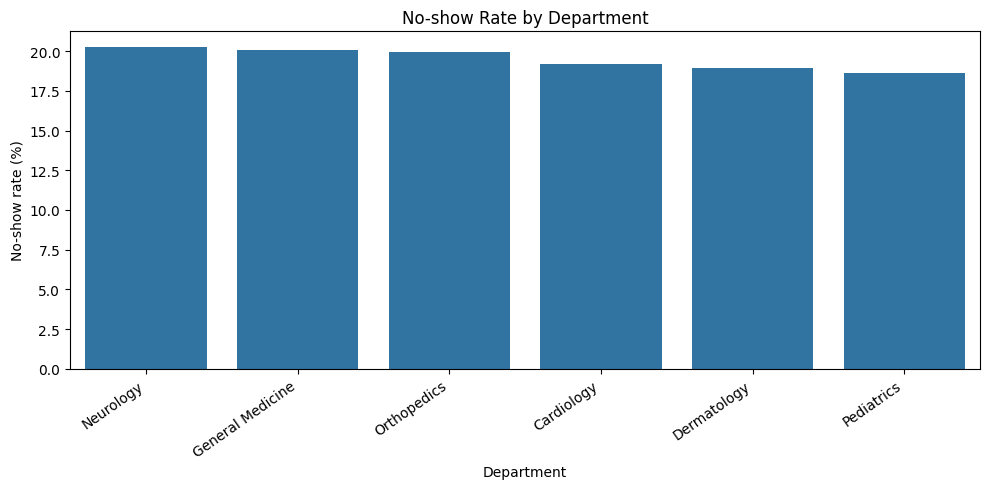

In [16]:

department_analysis = (
    known.groupby("Department", observed=True)
    .agg(
        Total_Appointments=("Appointment_ID", "nunique"),
        No_Shows=("No_Show_Flag", "sum")
    )
)

department_analysis["Shows"] = (
    department_analysis["Total_Appointments"]
    - department_analysis["No_Shows"]
)

department_analysis["No_Show_Rate_%"] = (
    department_analysis["No_Shows"]
    / department_analysis["Total_Appointments"] * 100
)

department_analysis = department_analysis.sort_values(
    "No_Show_Rate_%", ascending=False
)

display(department_analysis.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=department_analysis.reset_index(),
    x="Department",
    y="No_Show_Rate_%"
)
plt.title("No-show Rate by Department")
plt.xlabel("Department")
plt.ylabel("No-show rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


,Total_Appointments,No_Shows,No_Show_Rate_%
Lead_Time_Group,,,
Same day,592,78.0,13.18
1–3 days,1694,268.0,15.82
4–7 days,1208,223.0,18.46
8–14 days,831,203.0,24.43
15–30 days,581,182.0,31.33


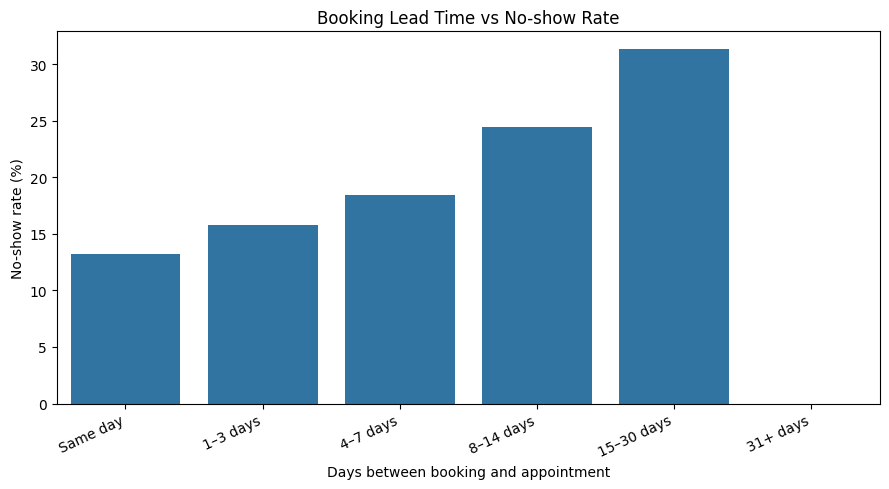

In [17]:

lead_analysis = (
    known.dropna(subset=["Lead_Time_Group"])
    .groupby("Lead_Time_Group", observed=True)
    .agg(
        Total_Appointments=("Appointment_ID", "nunique"),
        No_Shows=("No_Show_Flag", "sum")
    )
)

lead_analysis["No_Show_Rate_%"] = (
    lead_analysis["No_Shows"]
    / lead_analysis["Total_Appointments"] * 100
)

display(lead_analysis.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=lead_analysis.reset_index(),
    x="Lead_Time_Group",
    y="No_Show_Rate_%"
)
plt.title("Booking Lead Time vs No-show Rate")
plt.xlabel("Days between booking and appointment")
plt.ylabel("No-show rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


,Total_Appointments,No_Shows,No_Show_Rate_%
Appointment_Weekday,,,
Monday,707,134.0,18.95
Tuesday,692,131.0,18.93
Wednesday,722,148.0,20.50
Thursday,722,151.0,20.91
Friday,719,129.0,17.94
Saturday,662,147.0,22.21
Sunday,701,120.0,17.12


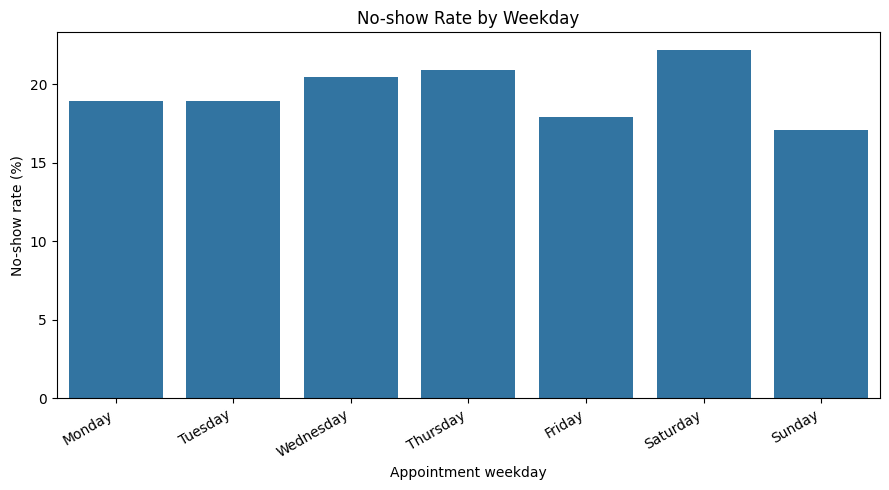

In [18]:

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_analysis = (
    known.groupby("Appointment_Weekday")
    .agg(
        Total_Appointments=("Appointment_ID", "nunique"),
        No_Shows=("No_Show_Flag", "sum")
    )
    .reindex(weekday_order)
)

weekday_analysis["No_Show_Rate_%"] = (
    weekday_analysis["No_Shows"]
    / weekday_analysis["Total_Appointments"] * 100
)

display(weekday_analysis.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=weekday_analysis.reset_index(),
    x="Appointment_Weekday",
    y="No_Show_Rate_%"
)
plt.title("No-show Rate by Weekday")
plt.xlabel("Appointment weekday")
plt.ylabel("No-show rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


,Total_Appointments,No_Shows,Group,No_Show_Rate_%
Reminder_Received,,,,
0,1174,223.0,No reminder record,18.99
1,3751,737.0,Reminder record available,19.65


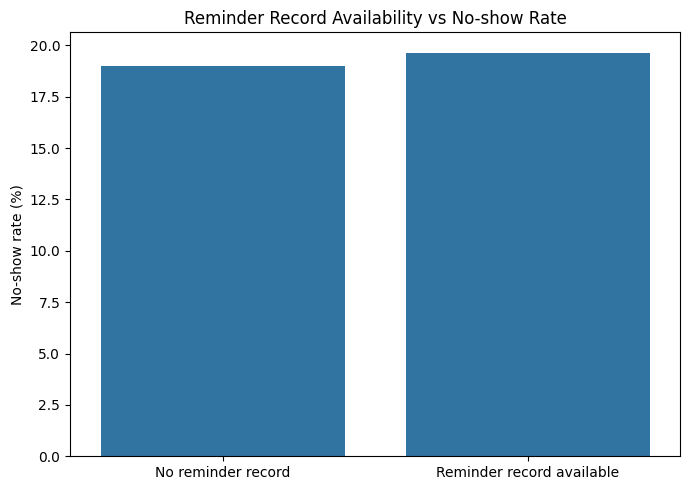

In [19]:

reminder_analysis = (
    known.groupby("Reminder_Received")
    .agg(
        Total_Appointments=("Appointment_ID", "nunique"),
        No_Shows=("No_Show_Flag", "sum")
    )
)

reminder_analysis["Group"] = reminder_analysis.index.map({
    0: "No reminder record",
    1: "Reminder record available"
})

reminder_analysis["No_Show_Rate_%"] = (
    reminder_analysis["No_Shows"]
    / reminder_analysis["Total_Appointments"] * 100
)

display(reminder_analysis.round(2))

plt.figure(figsize=(7, 5))
sns.barplot(
    data=reminder_analysis.reset_index(),
    x="Group",
    y="No_Show_Rate_%"
)
plt.title("Reminder Record Availability vs No-show Rate")
plt.xlabel("")
plt.ylabel("No-show rate (%)")
plt.tight_layout()
plt.show()


In [20]:

history = master.sort_values(
    ["Patient_ID", "Appointment_Date", "Appointment_ID"]
).copy()

history["No_Show_Flag"] = history["Status"].map({
    "Show": 0,
    "No-show": 1
})

# Shift by one appointment so current outcome is not included
history["Prior_Known_Visits"] = (
    history.groupby("Patient_ID")["No_Show_Flag"]
    .transform(lambda s: s.notna().shift(fill_value=False).cumsum())
)

history["Prior_No_Shows"] = (
    history.groupby("Patient_ID")["No_Show_Flag"]
    .transform(
        lambda s: s.eq(1).shift(fill_value=False).cumsum()
    )
)

history["Prior_No_Show_Rate"] = np.where(
    history["Prior_Known_Visits"] > 0,
    history["Prior_No_Shows"] / history["Prior_Known_Visits"],
    np.nan
)

history["Prior_Attendance_Group"] = pd.cut(
    history["Prior_No_Show_Rate"],
    bins=[-0.001, 0, 0.25, 0.50, 1.00],
    labels=[
        "No previous no-shows",
        "Low (up to 25%)",
        "Moderate (25–50%)",
        "High (over 50%)"
    ],
    include_lowest=True
)

prior_analysis = (
    history[history["No_Show_Flag"].notna()]
    .groupby("Prior_Attendance_Group", observed=True)
    .agg(
        Total_Appointments=("Appointment_ID", "nunique"),
        No_Shows=("No_Show_Flag", "sum")
    )
)

prior_analysis["No_Show_Rate_%"] = (
    prior_analysis["No_Shows"]
    / prior_analysis["Total_Appointments"] * 100
)

display(prior_analysis.round(2))


,Total_Appointments,No_Shows,No_Show_Rate_%
Prior_Attendance_Group,,,
No previous no-shows,2149,415.0,19.31
Low (up to 25%),253,46.0,18.18
Moderate (25–50%),693,122.0,17.60
High (over 50%),392,71.0,18.11


Total_Appointments  No_Shows  No_Show_Rate_%
Age_Group Locality                                              
36-50     Rural                    196      43.0           21.94
66+       Rural                    246      53.0           21.54
36-50     Urban                    530     110.0           20.75
51-65     Urban                    492     101.0           20.53
          Suburban                 339      69.0           20.35
66+       Urban                    343      69.0           20.12
          Suburban                 195      39.0           20.00
0-17      Urban                    278      55.0           19.78
18-35     Urban                    741     145.0           19.57
          Rural                    309      60.0           19.42
0-17      Suburban                 140      26.0           18.57
18-35     Suburban                 426      78.0           18.31
36-50     Suburban                 364      64.0           17.58
51-65     Rural                    207      32.0           15.46
0-17      Rural                    119      16.0           13.45

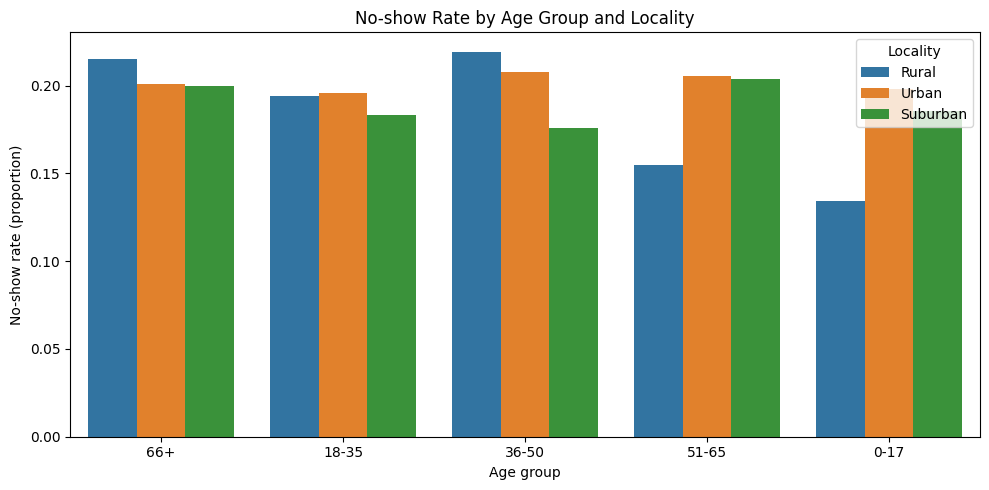

In [21]:

patient_group_analysis = (
    known.groupby(["Age_Group", "Locality"], dropna=False)
    .agg(
        Total_Appointments=("Appointment_ID", "nunique"),
        No_Shows=("No_Show_Flag", "sum")
    )
)

patient_group_analysis["No_Show_Rate_%"] = (
    patient_group_analysis["No_Shows"]
    / patient_group_analysis["Total_Appointments"] * 100
)

patient_group_analysis = patient_group_analysis.sort_values(
    "No_Show_Rate_%", ascending=False
)

display(patient_group_analysis.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=known,
    x="Age_Group",
    y="No_Show_Flag",
    hue="Locality",
    errorbar=None
)
plt.title("No-show Rate by Age Group and Locality")
plt.xlabel("Age group")
plt.ylabel("No-show rate (proportion)")
plt.tight_layout()
plt.show()


In [22]:

# Save updated master dataset with engineered features
master.to_csv("CareBridge_Cleaned_Master.csv", index=False)

# Export analysis tables to a single Excel workbook
with pd.ExcelWriter("CareBridge_EDA_Analysis.xlsx") as writer:
    department_analysis.to_excel(writer, sheet_name="Department Analysis")
    lead_analysis.to_excel(writer, sheet_name="Lead Time Analysis")
    weekday_analysis.to_excel(writer, sheet_name="Weekday Analysis")
    reminder_analysis.to_excel(writer, sheet_name="Reminder Analysis")
    prior_analysis.to_excel(writer, sheet_name="Prior Attendance")
    patient_group_analysis.to_excel(writer, sheet_name="Patient Groups")

print("EDA outputs saved successfully.")


EDA outputs saved successfully.


In [23]:
from google.colab import files
files.download("CareBridge_Cleaned_Master.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>